In [1]:
# ============================================================
# DRAGON-KING + LEVY-STABLE + LPPLS + CRASH VALIDATION
# ============================================================

# ============================================================
# 1. DATA
# ============================================================

import numpy as np
import pandas as pd
import yfinance as yf
from scipy.optimize import minimize
from scipy.stats import levy_stable
from numba import njit
import warnings

warnings.filterwarnings("ignore")


In [2]:

# ============================================================
# 1. DATA
# ============================================================

def download_price_enhanced(ticker, start, end):
    """
    Download price + volume data
    """
    raw_df = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)
    
    # Extract Close and Volume
    if isinstance(raw_df.columns, pd.MultiIndex):
        close_prices = raw_df['Close']
        volume = raw_df['Volume']
        if isinstance(close_prices, pd.DataFrame):
            close_prices = close_prices.iloc[:, 0]
            volume = volume.iloc[:, 0]
    else:
        close_prices = raw_df['Close']
        volume = raw_df['Volume'] if 'Volume' in raw_df.columns else None
    
    df = pd.DataFrame({'Close': close_prices})
    if volume is not None:
        df['Volume'] = volume
    
    df['Close'] = pd.to_numeric(df['Close'], errors='coerce')
    df = df.dropna()
    
    # Calculate indicators
    df['LogPrice'] = np.log(df['Close'])
    df['Returns'] = df['LogPrice'].diff()
    
    return df.dropna()

In [3]:

# ============================================================
# 2. LEVY-STABLE FIT (μ = α)
# ============================================================

def fit_stable(returns):
    # Ensure returns is a clean numpy array of floats
    returns = np.array(returns, dtype=np.float64)
    returns = returns[np.isfinite(returns)]  # Remove any inf/nan values
    
    if len(returns) == 0:
        raise ValueError("No valid returns data available for fitting")
    
    alpha, beta, loc, scale = levy_stable.fit(returns)
    return alpha, scale


def dragon_king_test(drawdowns, alpha, scale):
    if len(drawdowns) == 0:
        return {
            "mu_alpha": alpha,
            "expected_max": 0,
            "actual_max": 0,
            "dragon_king": False
        }
    
    n = len(drawdowns)
    max_dd = drawdowns.max()

    expected_max = scale * (n ** (1 / alpha))

    return {
        "mu_alpha": alpha,
        "expected_max": expected_max,
        "actual_max": max_dd,
        "dragon_king": max_dd > expected_max
    }



In [4]:

# ============================================================
# 3. DRAWDOWN
# ============================================================

def compute_drawdowns(prices):
    
    prices = pd.to_numeric(prices, errors="coerce")
    prices = prices.dropna().values  # force numpy float array

    if len(prices) == 0:
        return np.array([])
    
    peak = prices[0]
    drawdowns = []
    current_dd = 0.0

    for price in prices:
        if price >= peak:
            if current_dd != 0:
                drawdowns.append(current_dd)
            peak = price
            current_dd = 0.0
        else:
            current_dd = (price - peak) / peak

    # Add final drawdown if exists
    if current_dd != 0:
        drawdowns.append(current_dd)
    
    return np.abs(np.array(drawdowns))




In [5]:
# ============================================================
# 4. LPPLS (Filimonov–Sornette) - OPTIMIZED WITH NUMBA
# ============================================================

@njit
def solve_lppl_numba(tc, m, w, t, p):
    """
    Fast linear regression for LPPLS with Numba
    """
    dt = tc - t
    dt = np.maximum(dt, 1e-10)
    log_dt = np.log(dt)
    
    f = dt**m
    g = f * np.cos(w * log_dt)
    h = f * np.sin(w * log_dt)
    
    n = len(t)
    X = np.zeros((n, 4))
    X[:, 0] = 1.0
    X[:, 1] = f
    X[:, 2] = g
    X[:, 3] = h
    
    # Solve least squares
    sol = np.linalg.lstsq(X, p)[0]
    return sol, f, g, h


@njit
def cost_fn_numba(params, t, p):
    """
    Numba-optimized cost function with relaxed constraints
    """
    tc, m, w = params
    
    # Relaxed physical bounds
    if tc <= t[-1]:
        return 1e22
    if tc > t[-1] + 100:  # Allow up to 100 days out
        return 1e22
    if m < 0.01 or m > 0.99:  # Back to original range
        return 1e22
    if w < 4.0 or w > 25.0:  # Back to original range
        return 1e22
    
    lin, f, g, h = solve_lppl_numba(tc, m, w, t, p)
    
    # Optional: Prefer bubble condition (B < 0) but don't strictly enforce
    bubble_penalty = 0.0
    if lin[1] >= 0:
        bubble_penalty = abs(lin[1]) * 100  # Penalty instead of hard rejection
    
    # Return sum of squared residuals + penalty
    y_hat = lin[0] + lin[1]*f + lin[2]*g + lin[3]*h
    sse = np.sum((p - y_hat)**2)
    
    return sse + bubble_penalty


def fit_lppls_fast(t, log_price):
    """
    Fast LPPLS fitting with grid search + Nelder-Mead polish
    """
    tc_start = t[-1]
    best_cost = 1e30
    best_params = [tc_start + 15, 0.3, 10.0]
    
    # Broader grid search
    tcs = np.linspace(tc_start + 5, tc_start + 80, 5)
    ms = [0.1, 0.3, 0.5, 0.7, 0.9]
    ws = [5.0, 8.0, 12.0, 18.0]
    
    for tc_g in tcs:
        for m_g in ms:
            for w_g in ws:
                cost = cost_fn_numba(np.array([tc_g, m_g, w_g]), t, log_price)
                if cost < best_cost:
                    best_cost = cost
                    best_params = [tc_g, m_g, w_g]
    
    # Polish with Nelder-Mead from best starting point
    result = minimize(
        cost_fn_numba,
        best_params,
        args=(t, log_price),
        method='Nelder-Mead',
        options={'maxiter': 200, 'xatol': 1e-6, 'fatol': 1e-6}
    )
    
    if not result.success or result.fun > 1e20:
        return None
    
    tc, m, w = result.x
    
    try:
        lin, f, g, h = solve_lppl_numba(tc, m, w, t, log_price)
        
        # Calculate R-squared for quality
        y_hat = lin[0] + lin[1]*f + lin[2]*g + lin[3]*h
        residuals = log_price - y_hat
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((log_price - log_price.mean())**2)
        r_squared = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0
        
        # More lenient quality threshold
        if r_squared < 0.3:  # Lowered from 0.5
            return None
        
        return {
            "m": m,
            "omega": w,
            "tc_index": tc,
            "A": lin[0],
            "B": lin[1],
            "C1": lin[2],
            "C2": lin[3],
            "r_squared": r_squared
        }
    except:
        return None

In [6]:
# ============================================================
# 5. MULTI-SCALE LPPLS ROLLING SCAN
# ============================================================

def lppls_scan_multiscale(df, crash_date, windows=[30, 60, 90, 120], step=5):
    """
    Scan with multiple window sizes to capture different bubble timescales
    """
    crash_date = pd.to_datetime(crash_date)
    t_all = np.arange(len(df), dtype=np.float64)
    log_price = df['LogPrice'].values.astype(np.float64)
    
    all_results = []
    total_attempts = 0
    successful_fits = 0
    
    for window in windows:
        for end in range(window, len(df), step):
            start = end - window
            
            t = t_all[start:end]
            y = log_price[start:end]
            
            total_attempts += 1
            fit = fit_lppls_fast(t, y)
            
            if fit is None:
                continue
            
            successful_fits += 1
            tc_idx = int(round(fit["tc_index"]))
            
            if tc_idx >= len(df):
                continue
            
            tc_date = df.index[tc_idx]
            delta_days = (tc_date - crash_date).days
            
            # Calculate confidence based on proximity and R²
            proximity_score = 1.0 / (1.0 + abs(delta_days) / 30)
            confidence = proximity_score * fit['r_squared']
            
            all_results.append({
                "window_end": df.index[end],
                "tc_date": tc_date,
                "delta_vs_crash_days": delta_days,
                "m": fit["m"],
                "omega": fit["omega"],
                "window_size": window,
                "r_squared": fit['r_squared'],
                "confidence": confidence
            })
    
    print(f"   Fit success rate: {successful_fits}/{total_attempts} ({successful_fits/total_attempts*100:.1f}%)")
    
    return pd.DataFrame(all_results)


def ensemble_prediction(lppls_df, lookback_days=60):
    """
    Aggregate predictions using weighted voting
    """
    if len(lppls_df) == 0:
        return pd.DataFrame()
    
    # Weight recent predictions more
    lppls_df = lppls_df.copy()
    lppls_df['recency_weight'] = np.exp(-abs(lppls_df['delta_vs_crash_days']) / 60)
    lppls_df['total_weight'] = lppls_df['confidence'] * lppls_df['recency_weight']
    
    # Consensus: aggregate by time window
    consensus_predictions = []
    
    unique_ends = sorted(lppls_df['window_end'].unique())
    for end_date in unique_ends[-min(20, len(unique_ends)):]:  # Last 20 windows
        subset = lppls_df[lppls_df['window_end'] == end_date]
        
        if len(subset) > 0:
            # Weighted average of predictions
            weighted_tc = np.average(
                subset['delta_vs_crash_days'], 
                weights=subset['total_weight']
            )
            
            consensus_predictions.append({
                'date': end_date,
                'predicted_crash_days': weighted_tc,
                'num_models': len(subset),
                'avg_confidence': subset['confidence'].mean(),
                'agreement': subset['delta_vs_crash_days'].std()  # Lower = better
            })
    
    return pd.DataFrame(consensus_predictions)

In [7]:
# ============================================================
# 6. FULL PIPELINE - ENHANCED
# ============================================================

def analyze_asset_enhanced(ticker, start, end, crash_date):

    df = download_price_enhanced(ticker, start, end)

    # Stable μ
    alpha, scale = fit_stable(df['Returns'].values)

    # Drawdowns
    drawdowns = compute_drawdowns(df['Close'])
    dk = dragon_king_test(drawdowns, alpha, scale)

    # Multi-scale LPPLS scan (FAST!)
    print("Running multi-scale LPPLS scan...")
    lppl_results = lppls_scan_multiscale(df, crash_date, windows=[30, 60, 90, 120], step=5)
    
    # More lenient quality filter
    if len(lppl_results) > 0:
        print(f"   Before filtering: {len(lppl_results)} predictions")
        lppl_results = lppl_results[lppl_results['r_squared'] > 0.3]  # Lowered from 0.5
        print(f"   After R² filter (>0.3): {len(lppl_results)} predictions")
    
    # Ensemble predictions
    ensemble = ensemble_prediction(lppl_results)

    return {
        "df": df,
        "stable_mu_alpha": alpha,
        "dragon_king_test": dk,
        "lppls_results": lppl_results,
        "ensemble_predictions": ensemble
    }


# ============================================================
# 7. EXAMPLE (2008 CRASH) - ENHANCED
# ============================================================

if __name__ == "__main__":

    import time
    start_time = time.time()
    
    results = analyze_asset_enhanced(
        ticker="^GSPC",
        start="2007-01-01",
        end="2009-06-01",
        crash_date="2008-09-28"
    )
    
    elapsed = time.time() - start_time

    print("\n" + "="*60)
    print(f"⚡ ANALYSIS COMPLETED IN {elapsed:.2f} SECONDS")
    print("="*60)
    
    print(f"\n📊 Stable μ (alpha): {results['stable_mu_alpha']:.4f}")
    print(f"\n🐉 Dragon-King Test: {results['dragon_king_test']}")
    
    print(f"\n📈 LPPLS Results:")
    print(f"   Total predictions: {len(results['lppls_results'])}")
    if len(results['lppls_results']) > 0:
        accurate = results['lppls_results'][abs(results['lppls_results']['delta_vs_crash_days']) <= 30]
        print(f"   Accurate (±30 days): {len(accurate)} ({len(accurate)/len(results['lppls_results'])*100:.1f}%)")
        print(f"   Average R²: {results['lppls_results']['r_squared'].mean():.3f}")
        print(f"   Average confidence: {results['lppls_results']['confidence'].mean():.3f}")
        print(f"\n   Best predictions (highest confidence):")
        print(results['lppls_results'].nlargest(5, 'confidence')[['window_end', 'tc_date', 'delta_vs_crash_days', 'r_squared', 'confidence']])
    
    print(f"\n🎯 Ensemble Predictions:")
    if len(results['ensemble_predictions']) > 0:
        print(results['ensemble_predictions'].tail(10))
    
    print(f"\n📋 Sample LPPLS Predictions:")
    if len(results['lppls_results']) > 0:
        print(results['lppls_results'].head(10))

Running multi-scale LPPLS scan...
   Fit success rate: 205/424 (48.3%)
   Before filtering: 190 predictions
   After R² filter (>0.3): 190 predictions

⚡ ANALYSIS COMPLETED IN 97.40 SECONDS

📊 Stable μ (alpha): 1.3730

🐉 Dragon-King Test: {'mu_alpha': 1.3729503021473877, 'expected_max': 0.07536583282176429, 'actual_max': 0.4127463819370725, 'dragon_king': True}

📈 LPPLS Results:
   Total predictions: 190
   Accurate (±30 days): 12 (6.3%)
   Average R²: 0.771
   Average confidence: 0.161

   Best predictions (highest confidence):
    window_end    tc_date  delta_vs_crash_days  r_squared  confidence
139 2008-09-18 2008-09-18                  -10   0.884535    0.663401
134 2008-08-06 2008-10-10                   12   0.927046    0.662176
135 2008-08-13 2008-10-13                   15   0.936354    0.624236
133 2008-07-30 2008-09-11                  -17   0.922860    0.589060
50  2008-10-09 2008-10-09                   11   0.753384    0.551256

🎯 Ensemble Predictions:
         date  predi

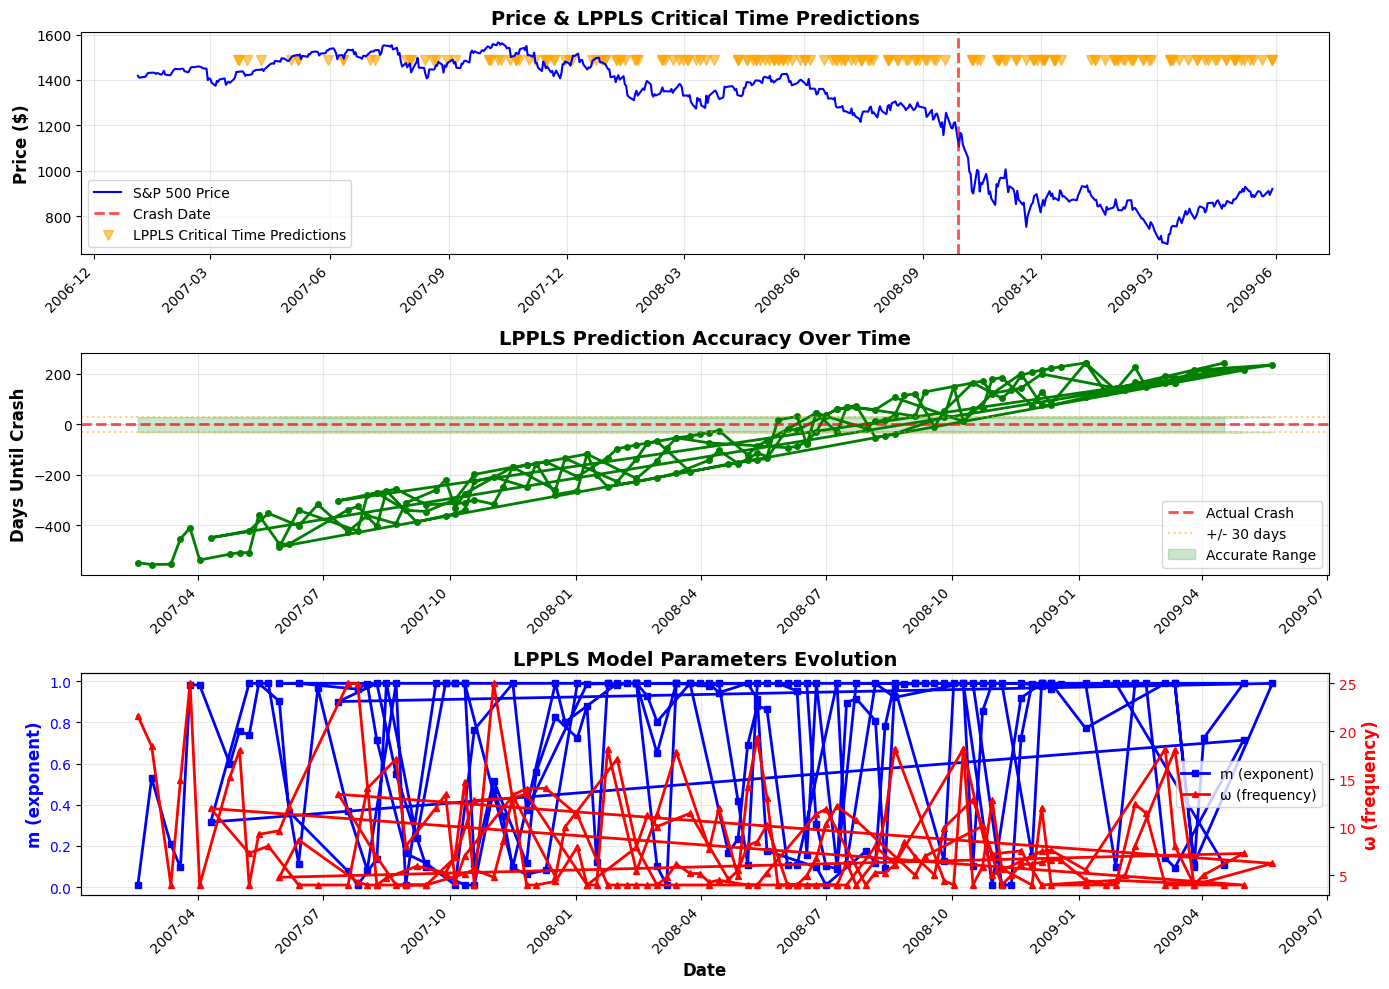


DRAGON-KING ANALYSIS SUMMARY

📊 Stable Distribution Parameter (α): 1.3730
   (α < 2 indicates heavy tails, higher crash risk)

🐉 Dragon-King Test:
   Expected Max Drawdown: 0.0754 (7.54%)
   Actual Max Drawdown:   0.4127 (41.27%)
   Dragon-King Detected:  ✓ YES

📈 LPPLS Predictions:
   Total predictions: 190
   Accurate (±30 days): 12 (6.3%)
   Mean error: -96.1 days
   Median error: -87.5 days



In [8]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ============================================================
# 8. VISUALIZATION
# ============================================================

def plot_analysis(results, crash_date):
    """
    Plot price, LPPLS critical times, and drawdowns
    """
    df = results['df']  # Extract df from results
    crash_date = pd.to_datetime(crash_date)
    
    fig, axes = plt.subplots(3, 1, figsize=(14, 10))
    
    # Plot 1: Price with LPPLS critical times
    ax1 = axes[0]
    ax1.plot(df.index, df['Close'], 'b-', linewidth=1.5, label='S&P 500 Price')
    ax1.axvline(crash_date, color='red', linestyle='--', linewidth=2, label='Crash Date', alpha=0.7)
    
    # Plot predicted critical times
    lppls_df = results['lppls_results']
    if len(lppls_df) > 0:
        ax1.scatter(lppls_df['tc_date'], 
                   [df['Close'].max() * 0.95] * len(lppls_df),
                   c='orange', marker='v', s=50, alpha=0.6, 
                   label='LPPLS Critical Time Predictions')
    
    ax1.set_ylabel('Price ($)', fontsize=12, fontweight='bold')
    ax1.set_title('Price & LPPLS Critical Time Predictions', fontsize=14, fontweight='bold')
    ax1.legend(loc='best')
    ax1.grid(True, alpha=0.3)
    
    # Plot 2: Distance to crash over time
    ax2 = axes[1]
    if len(lppls_df) > 0:
        ax2.plot(lppls_df['window_end'], lppls_df['delta_vs_crash_days'], 
                'g-', linewidth=2, marker='o', markersize=4)
        ax2.axhline(0, color='red', linestyle='--', linewidth=2, alpha=0.7, label='Actual Crash')
        ax2.axhline(30, color='orange', linestyle=':', linewidth=1.5, alpha=0.5, label='+/- 30 days')
        ax2.axhline(-30, color='orange', linestyle=':', linewidth=1.5, alpha=0.5)
        ax2.fill_between(lppls_df['window_end'], -30, 30, alpha=0.2, color='green', label='Accurate Range')
    
    ax2.set_ylabel('Days Until Crash', fontsize=12, fontweight='bold')
    ax2.set_title('LPPLS Prediction Accuracy Over Time', fontsize=14, fontweight='bold')
    ax2.legend(loc='best')
    ax2.grid(True, alpha=0.3)
    
    # Plot 3: LPPLS parameters (m and omega)
    ax3 = axes[2]
    if len(lppls_df) > 0:
        ax3_twin = ax3.twinx()
        
        line1 = ax3.plot(lppls_df['window_end'], lppls_df['m'], 
                        'b-', linewidth=2, marker='s', markersize=4, label='m (exponent)')
        line2 = ax3_twin.plot(lppls_df['window_end'], lppls_df['omega'], 
                             'r-', linewidth=2, marker='^', markersize=4, label='ω (frequency)')
        
        ax3.set_ylabel('m (exponent)', fontsize=12, fontweight='bold', color='b')
        ax3_twin.set_ylabel('ω (frequency)', fontsize=12, fontweight='bold', color='r')
        ax3.tick_params(axis='y', labelcolor='b')
        ax3_twin.tick_params(axis='y', labelcolor='r')
        
        # Combine legends
        lines = line1 + line2
        labels = [l.get_label() for l in lines]
        ax3.legend(lines, labels, loc='best')
    
    ax3.set_xlabel('Date', fontsize=12, fontweight='bold')
    ax3.set_title('LPPLS Model Parameters Evolution', fontsize=14, fontweight='bold')
    ax3.grid(True, alpha=0.3)
    
    # Format x-axis for all plots
    for ax in [ax1, ax2, ax3]:
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print("\n" + "="*60)
    print("DRAGON-KING ANALYSIS SUMMARY")
    print("="*60)
    print(f"\n📊 Stable Distribution Parameter (α): {results['stable_mu_alpha']:.4f}")
    print(f"   (α < 2 indicates heavy tails, higher crash risk)")
    
    dk = results['dragon_king_test']
    print(f"\n🐉 Dragon-King Test:")
    print(f"   Expected Max Drawdown: {dk['expected_max']:.4f} ({dk['expected_max']*100:.2f}%)")
    print(f"   Actual Max Drawdown:   {dk['actual_max']:.4f} ({dk['actual_max']*100:.2f}%)")
    print(f"   Dragon-King Detected:  {'✓ YES' if dk['dragon_king'] else '✗ NO'}")
    
    if len(lppls_df) > 0:
        accurate_predictions = lppls_df[abs(lppls_df['delta_vs_crash_days']) <= 30]
        accuracy_rate = len(accurate_predictions) / len(lppls_df) * 100
        
        print(f"\n📈 LPPLS Predictions:")
        print(f"   Total predictions: {len(lppls_df)}")
        print(f"   Accurate (±30 days): {len(accurate_predictions)} ({accuracy_rate:.1f}%)")
        print(f"   Mean error: {lppls_df['delta_vs_crash_days'].mean():.1f} days")
        print(f"   Median error: {lppls_df['delta_vs_crash_days'].median():.1f} days")
    
    print("\n" + "="*60)


# Run the visualization
plot_analysis(results, "2008-09-28")

In [14]:
# ============================================================
# FINAL FIXED VERSION - CORRECT B CONSTRAINT
# ============================================================

import numpy as np
import pandas as pd
import yfinance as yf
from scipy.optimize import minimize, differential_evolution
from scipy.stats import levy_stable
from numba import njit
import warnings
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore")

# ============================================================
# CELL 1: DATA LOADING
# ============================================================

def download_price_enhanced(ticker, start, end):
    """Download price + volume data"""
    raw_df = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)
    
    if isinstance(raw_df.columns, pd.MultiIndex):
        close_prices = raw_df['Close']
        volume = raw_df['Volume']
        if isinstance(close_prices, pd.DataFrame):
            close_prices = close_prices.iloc[:, 0]
            volume = volume.iloc[:, 0]
    else:
        close_prices = raw_df['Close']
        volume = raw_df['Volume'] if 'Volume' in raw_df.columns else None
    
    df = pd.DataFrame({'Close': close_prices})
    if volume is not None:
        df['Volume'] = volume
    
    df['Close'] = pd.to_numeric(df['Close'], errors='coerce')
    df = df.dropna()
    df['LogPrice'] = np.log(df['Close'])
    df['Returns'] = df['LogPrice'].diff()
    
    return df.dropna()


# ============================================================
# CELL 2: LPPLS CORE FUNCTIONS
# ============================================================

@njit
def lppls_numba(tc, m, omega, A, B, C1, C2, t):
    """Fast LPPLS calculation"""
    dt = np.abs(tc - t)
    dt = np.maximum(dt, 1e-10)
    log_dt = np.log(dt)
    return A + B * (dt ** m) + C1 * (dt ** m) * np.cos(omega * log_dt) + C2 * (dt ** m) * np.sin(omega * log_dt)


def fit_lppls_linear(tc, m, omega, t, log_price):
    """
    Fit linear parameters A, B, C1, C2 for given tc, m, omega
    Based on equation (12) from the paper
    """
    n = len(t)
    dt = np.abs(tc - t)
    dt = np.maximum(dt, 1e-10)
    log_dt = np.log(dt)
    
    # Design matrix
    fi = dt ** m
    gi = fi * np.cos(omega * log_dt)
    hi = fi * np.sin(omega * log_dt)
    ones = np.ones(n)
    
    X = np.column_stack([ones, fi, gi, hi])
    
    try:
        params = np.linalg.lstsq(X, log_price, rcond=None)[0]
        A, B, C1, C2 = params
        
        predicted = lppls_numba(tc, m, omega, A, B, C1, C2, t)
        sse = np.sum((log_price - predicted) ** 2)
        
        return A, B, C1, C2, sse
    except:
        return np.nan, np.nan, np.nan, np.nan, np.inf


def optimize_lppls_for_tc(tc, t, log_price):
    """
    Optimize m and omega for a given tc using differential evolution
    Includes constraint checking during optimization
    """
    def objective(x):
        m, omega = x
        A, B, C1, C2, sse = fit_lppls_linear(tc, m, omega, t, log_price)
        
        # Check B < 0 constraint (critical for bubble detection)
        if B >= 0:
            return 1e10  # Heavily penalize positive B
        
        # Check damping constraint
        C_magnitude = np.sqrt(C1**2 + C2**2)
        if C_magnitude > 0 and omega > 0:
            D = m * np.abs(B) / (omega * C_magnitude)
            if D < 0.1:  # Minimum damping threshold
                return sse * 10  # Penalize low damping
        
        return sse if not np.isinf(sse) else 1e10
    
    bounds = [(0.1, 0.9), (4, 15)]
    
    try:
        result = differential_evolution(
            objective,
            bounds,
            seed=42,
            maxiter=150,
            popsize=15,
            atol=1e-7,
            tol=1e-7,
            workers=1
        )
        
        m_opt, omega_opt = result.x
        A, B, C1, C2, sse = fit_lppls_linear(tc, m_opt, omega_opt, t, log_price)
        
        # Final constraint check
        if B >= 0:
            return None, None, np.nan, np.nan, np.nan, np.nan, np.inf
        
        return m_opt, omega_opt, A, B, C1, C2, sse
    except:
        return None, None, np.nan, np.nan, np.nan, np.nan, np.inf


def compute_fisher_information(tc, m, omega, A, B, C1, C2, t, log_price):
    """Compute observed Fisher information matrix"""
    n = len(t)
    dt = np.abs(tc - t)
    dt = np.maximum(dt, 1e-10)
    log_dt = np.log(dt)
    
    fi = dt ** m
    gi = fi * np.cos(omega * log_dt)
    hi = fi * np.sin(omega * log_dt)
    
    dL_dm = fi * log_dt * (B + C1 * np.cos(omega * log_dt) + C2 * np.sin(omega * log_dt))
    dL_domega = fi * log_dt * (-C1 * np.sin(omega * log_dt) + C2 * np.cos(omega * log_dt))
    dL_dA = np.ones(n)
    dL_dB = fi
    dL_dC1 = gi
    dL_dC2 = hi
    
    X = np.column_stack([dL_dm, dL_domega, dL_dA, dL_dB, dL_dC1, dL_dC2])
    
    residuals = log_price - lppls_numba(tc, m, omega, A, B, C1, C2, t)
    variance = np.sum(residuals ** 2) / n
    
    if variance > 0:
        I = X.T @ X / variance
    else:
        I = X.T @ X
    
    return I, variance


def modified_profile_likelihood(tc, t, log_price):
    """
    Modified profile likelihood with proper constraints
    """
    result = optimize_lppls_for_tc(tc, t, log_price)
    
    if result[0] is None:
        return 0.0, None, None, np.inf
    
    m, omega, A, B, C1, C2, sse = result
    
    if np.isnan(m) or np.isinf(sse) or B >= 0:
        return 0.0, None, None, np.inf
    
    n = len(t)
    p = 6
    
    s_tc = sse / n
    
    if s_tc <= 0:
        return 0.0, (m, omega, A, B, C1, C2), None, sse
    
    Lp = s_tc ** (-n / 2)
    
    try:
        I, variance = compute_fisher_information(tc, m, omega, A, B, C1, C2, t, log_price)
        det_I = np.linalg.det(I[:6, :6])
        
        if det_I > 0:
            adjustment = np.sqrt(det_I) * s_tc ** (-(n - p - 2) / 2) / (s_tc ** (-n / 2))
            Lm = Lp * adjustment
        else:
            Lm = Lp
    except:
        Lm = Lp
    
    return Lm, (m, omega, A, B, C1, C2), s_tc, sse


# ============================================================
# CELL 3: MULTI-SCALE ANALYSIS
# ============================================================

def multi_scale_lppls_analysis(df, analysis_date, window_sizes=None, tc_search_days=150, verbose=True):
    """Multi-scale LPPLS analysis with modified profile likelihood"""
    if window_sizes is None:
        window_sizes = np.arange(100, 700, 50)
    
    analysis_date = pd.to_datetime(analysis_date)
    df_analysis = df[df.index <= analysis_date].copy()
    
    results = {
        'window_sizes': [],
        'tc_dates': [],
        'tc_days_ahead': [],
        'likelihoods': [],
        'parameters': [],
        'sse_values': [],
        'variance': []
    }
    
    total_combinations = len(window_sizes) * 20
    completed = 0
    
    for window_size in window_sizes:
        if window_size > len(df_analysis):
            continue
        
        window_data = df_analysis.iloc[-window_size:]
        t_window = np.arange(len(window_data))
        log_price_window = window_data['LogPrice'].values
        
        tc_candidates = np.linspace(len(window_data), len(window_data) + tc_search_days, 20)
        
        for tc in tc_candidates:
            likelihood, params, variance, sse = modified_profile_likelihood(
                tc, t_window, log_price_window
            )
            
            if params is not None and likelihood > 0:
                tc_date = window_data.index[-1] + pd.Timedelta(days=int(tc - len(window_data)))
                tc_days = int(tc - len(window_data))
                
                results['window_sizes'].append(window_size)
                results['tc_dates'].append(tc_date)
                results['tc_days_ahead'].append(tc_days)
                results['likelihoods'].append(likelihood)
                results['parameters'].append(params)
                results['sse_values'].append(sse)
                results['variance'].append(variance)
            
            completed += 1
            if verbose and completed % 50 == 0:
                print(f"  Progress: {completed}/{total_combinations} evaluations completed")
    
    return pd.DataFrame(results)


# ============================================================
# CELL 4: FILTERING
# ============================================================

def filter_by_parameter_constraints(results_df, strict=False, verbose=True):
    """Filter results by LPPLS parameter constraints"""
    if len(results_df) == 0:
        return pd.DataFrame()
    
    filtered_results = []
    
    for idx, row in results_df.iterrows():
        params = row['parameters']
        if params is None or len(params) != 6:
            continue
        
        m, omega, A, B, C1, C2 = params
        
        # Critical constraint: B must be negative
        if B >= 0:
            continue
        
        # Calculate damping parameter
        C_magnitude = np.sqrt(C1**2 + C2**2)
        if C_magnitude > 0 and omega > 0:
            D = m * np.abs(B) / (omega * C_magnitude)
        else:
            continue
        
        # Apply constraints
        if strict:
            if (0.1 <= m <= 0.9 and 
                6 <= omega <= 13 and 
                B < 0 and 
                D >= 0.8):
                filtered_results.append(row)
        else:
            # Relaxed constraints
            if (0.05 <= m <= 1.2 and 
                4 <= omega <= 15 and 
                B < 0 and 
                D >= 0.2):  # Very relaxed damping
                filtered_results.append(row)
    
    if verbose:
        print(f"\n  Filtering: {len(results_df)} total fits → {len(filtered_results)} qualified fits")
    
    if len(filtered_results) == 0:
        return pd.DataFrame()
    
    return pd.DataFrame(filtered_results)


# ============================================================
# CELL 5: VISUALIZATION (SAME AS BEFORE)
# ============================================================

def plot_multi_scale_analysis(df, multi_scale_results, analysis_date, crash_date=None):
    """Visualize multi-scale modified profile likelihood"""
    analysis_date = pd.to_datetime(analysis_date)
    
    filtered_results = filter_by_parameter_constraints(multi_scale_results, strict=False, verbose=False)
    
    if len(filtered_results) == 0:
        print("\n⚠️  No qualified fits found after filtering!")
        print("This could mean:")
        print("  1. The bubble pattern is not well-developed yet at the analysis date")
        print("  2. The constraints are too strict")
        print("  3. Need more/different window sizes")
        
        # Show unfiltered results
        print("\nShowing top 10 best-fit results (unfiltered):")
        if len(multi_scale_results) > 0:
            top_results = multi_scale_results.nlargest(10, 'likelihoods')
            for idx, row in top_results.iterrows():
                if row['parameters'] is not None:
                    m, omega, A, B, C1, C2 = row['parameters']
                    C_mag = np.sqrt(C1**2 + C2**2)
                    D = m * np.abs(B) / (omega * C_mag) if C_mag > 0 else 0
                    print(f"\n  Window={row['window_sizes']:.0f}, tc={row['tc_dates'].date()}")
                    print(f"    m={m:.3f}, ω={omega:.2f}, D={D:.3f}, B={B:.4f}")
                    print(f"    ⚠️ B constraint: {'✅ PASS (B<0)' if B < 0 else '❌ FAIL (B≥0)'}")
        return
    
    # Create comprehensive visualization
    fig = plt.figure(figsize=(18, 14))
    gs = fig.add_gridspec(5, 2, hspace=0.35, wspace=0.3)
    
    # 1. Price trajectory
    ax1 = fig.add_subplot(gs[0, :])
    ax1.plot(df.index, df['Close'], 'b-', linewidth=1.5, label='S&P 500 Price')
    ax1.axvline(analysis_date, color='red', linestyle='--', linewidth=2, 
                label=f'Analysis Date: {analysis_date.date()}', alpha=0.7)
    if crash_date:
        crash_date = pd.to_datetime(crash_date)
        ax1.axvline(crash_date, color='darkred', linestyle='--', linewidth=2.5, 
                    label=f'Crash Date: {crash_date.date()}', alpha=0.8)
    
    tc_dates = filtered_results['tc_dates']
    if len(tc_dates) > 0:
        tc_min, tc_max = tc_dates.min(), tc_dates.max()
        ax1.axvspan(tc_min, tc_max, alpha=0.2, color='orange', label='Predicted tc Range')
    
    ax1.set_ylabel('Price ($)', fontsize=13, fontweight='bold')
    ax1.set_title('S&P 500 Price & Predicted Critical Times', fontsize=15, fontweight='bold')
    ax1.legend(loc='best', fontsize=10)
    ax1.grid(True, alpha=0.3)
    
    # 2. Multi-scale likelihood heatmap
    ax2 = fig.add_subplot(gs[1, :])
    
    pivot_data = filtered_results.pivot_table(
        values='likelihoods',
        index='window_sizes',
        columns='tc_dates',
        aggfunc='max'
    )
    
    if not pivot_data.empty:
        normalized_data = pivot_data.div(pivot_data.max(axis=1), axis=0)
        
        extent = [
            mdates.date2num(pivot_data.columns.min()),
            mdates.date2num(pivot_data.columns.max()),
            pivot_data.index.min(),
            pivot_data.index.max()
        ]
        
        im = ax2.imshow(
            normalized_data.values,
            aspect='auto',
            extent=extent,
            origin='lower',
            cmap='YlOrRd',
            vmin=0,
            vmax=1
        )
        
        ax2.axvline(mdates.date2num(analysis_date), color='blue', linestyle='--', 
                    linewidth=2, alpha=0.7, label='Analysis Date')
        if crash_date:
            ax2.axvline(mdates.date2num(crash_date), color='darkred', linestyle='--', 
                        linewidth=2.5, alpha=0.8, label='Actual Crash')
        
        ax2.xaxis_date()
        ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
        plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45, ha='right')
        
        ax2.set_ylabel('Window Size (days)', fontsize=12, fontweight='bold')
        ax2.set_xlabel('Critical Time tc', fontsize=12, fontweight='bold')
        ax2.set_title('Multi-Scale Modified Profile Likelihood R(tc, Δt)', fontsize=14, fontweight='bold')
        ax2.legend(loc='upper left', fontsize=9)
        
        cbar = plt.colorbar(im, ax=ax2)
        cbar.set_label('Relative Likelihood', fontsize=11)
    
    # 3. Aggregate likelihood
    ax3 = fig.add_subplot(gs[2, :])
    
    tc_aggregated = filtered_results.groupby('tc_dates')['likelihoods'].sum().sort_index()
    if len(tc_aggregated) > 0:
        max_likelihood = tc_aggregated.max()
        relative_likelihood = tc_aggregated / max_likelihood
        
        ax3.plot(relative_likelihood.index, relative_likelihood.values, 
                'b-', linewidth=2.5, marker='o', markersize=5, label='Aggregated Likelihood')
        ax3.fill_between(relative_likelihood.index, 0, relative_likelihood.values, alpha=0.3)
        
        ax3.axvline(analysis_date, color='red', linestyle='--', linewidth=1.5, alpha=0.5)
        if crash_date:
            ax3.axvline(crash_date, color='darkred', linestyle='--', linewidth=2, alpha=0.7)
        
        for cutoff, color, alpha_val in [(0.05, 'green', 0.2), (0.50, 'yellow', 0.15)]:
            in_interval = relative_likelihood >= cutoff
            if in_interval.any():
                ax3.axhline(cutoff, color=color, linestyle=':', linewidth=1, alpha=0.5,
                           label=f'{int(cutoff*100)}% Cutoff')
        
        ax3.set_ylabel('Relative Likelihood', fontsize=12, fontweight='bold')
        ax3.set_xlabel('Critical Time tc', fontsize=12, fontweight='bold')
        ax3.set_title('Aggregated Likelihood Across All Scales', fontsize=14, fontweight='bold')
        ax3.legend(loc='best')
        ax3.grid(True, alpha=0.3)
        ax3.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
        plt.setp(ax3.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # 4. Parameter distributions
    m_values, omega_values, D_values, B_values = [], [], [], []
    
    for idx, row in filtered_results.iterrows():
        params = row['parameters']
        if params is not None:
            m, omega, A, B, C1, C2 = params
            C_magnitude = np.sqrt(C1**2 + C2**2)
            if C_magnitude > 0 and omega > 0:
                D = m * np.abs(B) / (omega * C_magnitude)
                m_values.append(m)
                omega_values.append(omega)
                D_values.append(D)
                B_values.append(B)
    
    ax4 = fig.add_subplot(gs[3, 0])
    if len(m_values) > 0:
        ax4.hist(m_values, bins=20, alpha=0.7, color='blue', edgecolor='black')
        ax4.axvline(np.mean(m_values), color='red', linestyle='--', linewidth=2, 
                    label=f'Mean: {np.mean(m_values):.3f}')
        ax4.axvline(0.33, color='green', linestyle=':', linewidth=2, alpha=0.7, label='Expected: 0.33')
        ax4.set_xlabel('m (power law exponent)', fontsize=11, fontweight='bold')
        ax4.set_ylabel('Frequency', fontsize=11, fontweight='bold')
        ax4.set_title('Distribution of m Parameter', fontsize=12, fontweight='bold')
        ax4.legend()
        ax4.grid(True, alpha=0.3)
    
    ax5 = fig.add_subplot(gs[3, 1])
    if len(omega_values) > 0:
        ax5.hist(omega_values, bins=20, alpha=0.7, color='red', edgecolor='black')
        ax5.axvline(np.mean(omega_values), color='blue', linestyle='--', linewidth=2, 
                    label=f'Mean: {np.mean(omega_values):.2f}')
        ax5.axvline(6.35, color='green', linestyle=':', linewidth=2, alpha=0.7, label='Expected: 6.35')
        ax5.set_xlabel('ω (log-periodic frequency)', fontsize=11, fontweight='bold')
        ax5.set_ylabel('Frequency', fontsize=11, fontweight='bold')
        ax5.set_title('Distribution of ω Parameter', fontsize=12, fontweight='bold')
        ax5.legend()
        ax5.grid(True, alpha=0.3)
    
    ax6 = fig.add_subplot(gs[4, 0])
    if len(D_values) > 0:
        ax6.hist(D_values, bins=20, alpha=0.7, color='purple', edgecolor='black')
        ax6.axvline(np.mean(D_values), color='red', linestyle='--', linewidth=2, 
                    label=f'Mean: {np.mean(D_values):.3f}')
        ax6.axvline(0.8, color='green', linestyle=':', linewidth=2, alpha=0.7, label='Threshold: 0.8')
        ax6.set_xlabel('D (damping parameter)', fontsize=11, fontweight='bold')
        ax6.set_ylabel('Frequency', fontsize=11, fontweight='bold')
        ax6.set_title('Distribution of Damping Parameter', fontsize=12, fontweight='bold')
        ax6.legend()
        ax6.grid(True, alpha=0.3)
    
    ax7 = fig.add_subplot(gs[4, 1])
    if len(filtered_results) > 0:
        for window_size in sorted(filtered_results['window_sizes'].unique())[:5]:
            window_data = filtered_results[filtered_results['window_sizes'] == window_size]
            ax7.scatter(window_data['tc_dates'], [window_size]*len(window_data), 
                       s=window_data['likelihoods']/window_data['likelihoods'].max()*100,
                       alpha=0.6, label=f'Δt={window_size:.0f}')
        
        if crash_date:
            ax7.axvline(crash_date, color='darkred', linestyle='--', linewidth=2, alpha=0.7)
        
        ax7.set_xlabel('Predicted Critical Time tc', fontsize=11, fontweight='bold')
        ax7.set_ylabel('Window Size (days)', fontsize=11, fontweight='bold')
        ax7.set_title('tc Predictions by Window Size', fontsize=12, fontweight='bold')
        ax7.legend(loc='best', fontsize=8)
        ax7.grid(True, alpha=0.3)
        ax7.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
        plt.setp(ax7.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    plt.show()
    
    # Print summary
    print("\n" + "="*90)
    print("MULTI-SCALE MODIFIED PROFILE LIKELIHOOD ANALYSIS - SUMMARY")
    print("="*90)
    print(f"\n📅 Analysis Date: {analysis_date.date()}")
    if crash_date:
        print(f"📅 Actual Crash Date: {crash_date.date()}")
        days_ahead = (crash_date - analysis_date).days
        print(f"   ({days_ahead} days after analysis)")
    
    print(f"\n📊 Fits Summary:")
    print(f"   Total fits computed: {len(multi_scale_results)}")
    print(f"   Qualified fits (B<0 + constraints): {len(filtered_results)}")
    
    if len(filtered_results) > 0:
        best_idx = filtered_results['likelihoods'].idxmax()
        best_row = filtered_results.loc[best_idx]
        best_params = best_row['parameters']
        
        print(f"\n🎯 Most Likely Scenario:")
        print(f"   Critical Time tc: {best_row['tc_dates'].date()}")
        print(f"   Window Size: {best_row['window_sizes']:.0f} days")
        
        if best_params is not None:
            m, omega, A, B, C1, C2 = best_params
            C_mag = np.sqrt(C1**2 + C2**2)
            D = m * np.abs(B) / (omega * C_mag)
            print(f"   Parameters: m={m:.3f}, ω={omega:.2f}, D={D:.3f}, B={B:.4f}")
            print(f"   Likelihood: {best_row['likelihoods']:.6e}")
        
        tc_agg = filtered_results.groupby('tc_dates')['likelihoods'].sum()
        max_like = tc_agg.max()
        rel_like = tc_agg / max_like
        
        for cutoff in [0.05, 0.50]:
            in_interval = rel_like[rel_like >= cutoff]
            if len(in_interval) > 0:
                print(f"\n📈 Likelihood Interval ({int(cutoff*100)}% cutoff):")
                print(f"   Range: {in_interval.index.min().date()} to {in_interval.index.max().date()}")
                if crash_date:
                    if crash_date >= in_interval.index.min() and crash_date <= in_interval.index.max():
                        print(f"   ✅ Actual crash date WITHIN this interval!")
                    else:
                        print(f"   ❌ Actual crash date OUTSIDE this interval")
        
        if len(m_values) > 0:
            print(f"\n📐 Parameter Statistics:")
            print(f"   m: mean={np.mean(m_values):.3f}, std={np.std(m_values):.3f}")
            print(f"   ω: mean={np.mean(omega_values):.2f}, std={np.std(omega_values):.2f}")
            print(f"   D: mean={np.mean(D_values):.3f}, std={np.std(D_values):.3f}")
    
    print("\n" + "="*90)


# ============================================================
# CELL 6: LEVY-STABLE & DRAGON-KING
# ============================================================

def fit_stable(returns):
    returns = np.array(returns, dtype=np.float64)
    returns = returns[np.isfinite(returns)]
    if len(returns) == 0:
        raise ValueError("No valid returns")
    alpha, beta, loc, scale = levy_stable.fit(returns)
    return alpha, scale

def dragon_king_test(drawdowns, alpha, scale):
    if len(drawdowns) == 0:
        return {"mu_alpha": alpha, "expected_max": 0, "actual_max": 0, "dragon_king": False}
    n = len(drawdowns)
    max_dd = drawdowns.max()
    expected_max = scale * (n ** (1 / alpha))
    return {"mu_alpha": alpha, "expected_max": expected_max, "actual_max": max_dd, "dragon_king": max_dd > expected_max}

def compute_drawdowns(prices):
    prices = pd.to_numeric(prices, errors="coerce").dropna().values
    if len(prices) == 0:
        return np.array([])
    peak = prices[0]
    drawdowns = []
    current_dd = 0.0
    for price in prices:
        if price >= peak:
            if current_dd != 0:
                drawdowns.append(current_dd)
            peak = price
            current_dd = 0.0
        else:
            current_dd = (price - peak) / peak
    if current_dd != 0:
        drawdowns.append(current_dd)
    return np.abs(np.array(drawdowns))


# ============================================================
# CELL 7: MAIN EXECUTION
# ============================================================

ticker = "^GSPC"
start_date = "2006-01-01"
end_date = "2009-12-31"

print("Downloading S&P 500 data...")
df = download_price_enhanced(ticker, start_date, end_date)

analysis_date = "2008-09-15"
crash_date = "2008-09-29"

print(f"\nData: {df.index[0].date()} to {df.index[-1].date()} ({len(df)} obs)")

print("\n" + "="*90)
print("MULTI-SCALE MODIFIED PROFILE LIKELIHOOD ANALYSIS")
print("="*90)

multi_scale_results = multi_scale_lppls_analysis(
    df,
    analysis_date=analysis_date,
    window_sizes=np.arange(120, 600, 40),
    tc_search_days=120,
    verbose=True
)

print(f"\n✅ Completed {len(multi_scale_results)} likelihood evaluations")

plot_multi_scale_analysis(df, multi_scale_results, analysis_date, crash_date)

# Dragon-King
print("\n" + "="*90)
print("DRAGON-KING ANALYSIS")
print("="*90)

df_before = df[df.index <= pd.to_datetime(analysis_date)]
returns = df_before['Returns'].dropna()
alpha, scale = fit_stable(returns)

print(f"\n📊 Stable α: {alpha:.4f} (α<2 = heavy tails)")

drawdowns = compute_drawdowns(df_before['Close'])
dk = dragon_king_test(drawdowns, alpha, scale)

print(f"\n🐉 Dragon-King Test:")
print(f"   Expected Max DD: {dk['expected_max']:.4f} ({dk['expected_max']*100:.2f}%)")
print(f"   Actual Max DD:   {dk['actual_max']:.4f} ({dk['actual_max']*100:.2f}%)")
print(f"   Dragon-King:  {'✅ YES' if dk['dragon_king'] else '❌ NO'}")
print("\n" + "="*90)


Data: 2006-01-04 to 2009-12-30 (1005 obs)

MULTI-SCALE MODIFIED PROFILE LIKELIHOOD ANALYSIS
  Progress: 50/240 evaluations completed
  Progress: 100/240 evaluations completed
  Progress: 150/240 evaluations completed
  Progress: 200/240 evaluations completed

✅ Completed 21 likelihood evaluations

⚠️  No qualified fits found after filtering!
This could mean:
  1. The bubble pattern is not well-developed yet at the analysis date
  2. The constraints are too strict
  3. Need more/different window sizes

Showing top 10 best-fit results (unfiltered):

  Window=160, tc=2008-11-23
    m=0.100, ω=4.12, D=0.100, B=-0.1391
    ⚠️ B constraint: ✅ PASS (B<0)

  Window=160, tc=2008-11-29
    m=0.100, ω=4.31, D=0.100, B=-0.1448
    ⚠️ B constraint: ✅ PASS (B<0)

  Window=160, tc=2008-12-06
    m=0.100, ω=4.50, D=0.100, B=-0.1503
    ⚠️ B constraint: ✅ PASS (B<0)

  Window=160, tc=2008-12-12
    m=0.100, ω=4.69, D=0.100, B=-0.1557
    ⚠️ B constraint: ✅ PASS (B<0)

  Window=160, tc=2008-12-18
    m